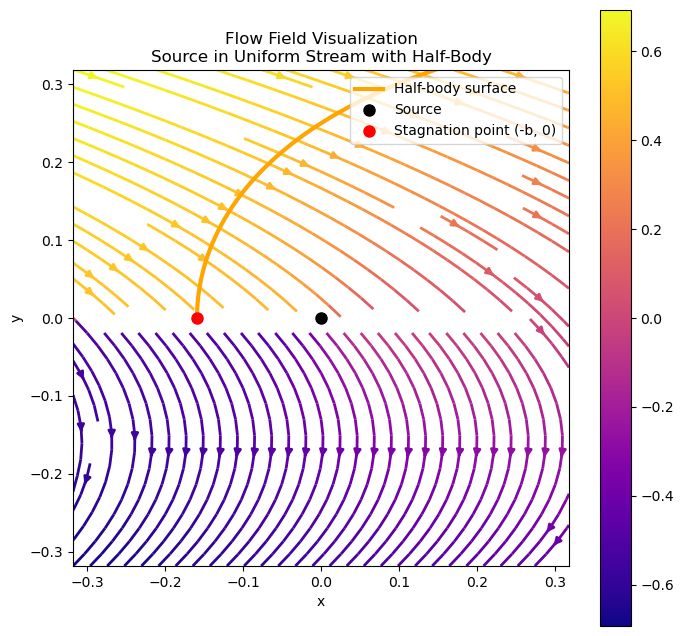

In [1]:
import numpy as np
import matplotlib.pyplot as plt

U = 1.0        
m = 1.0        

b = m / (2 * np.pi * U)  
theta = np.linspace(0.001, np.pi-0.001, 500)  # Avoid theta=0, pi (singularities)

r = b * (np.pi - theta) / np.sin(theta)
x = r * np.cos(theta)
y = r * np.sin(theta)

xgrid = np.linspace(-2*b, 2*b, 200)
ygrid = np.linspace(-2*b, 2*b, 200)
X, Y = np.meshgrid(xgrid, ygrid)

R = np.sqrt(X**2 + Y**2)
theta_grid = np.arctan2(Y, X)
psi = U * R * np.sin(theta_grid) + (m / (2 * np.pi)) * theta_grid  
phi = U * R * np.cos(theta_grid) + (m / (2 * np.pi)) * np.log(R)  

v_r = U * np.sin(theta_grid) + (m / (2 * np.pi)) * (1 / R)
v_theta = - (m / (2 * np.pi)) * (1 / R)

fig, ax = plt.subplots(figsize=(8, 8))

strm = ax.streamplot(X, Y, v_r, v_theta, color=psi, linewidth=2, cmap='plasma')
ax.set_title('Flow Field Visualization\nSource in Uniform Stream with Half-Body')

ax.plot(x, y, lw=3, color='orange', label="Half-body surface")

ax.plot(0, 0, 'ko', ms=8, label="Source")
ax.plot(-b, 0, 'ro', ms=8, label="Stagnation point (-b, 0)")

ax.set_xlim([-2*b, 2*b])
ax.set_ylim([-2*b, 2*b])
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend(loc="upper right")
ax.set_aspect('equal', adjustable='box')

fig.colorbar(strm.lines)

plt.show()